# 1. Effective Rydberg Hamiltonian and particle-number-resolved spectrum

**Question:** how do the four occupation-conserving exchange processes
organize the spectrum? This notebook reconstructs a small model, then plots
the saved $L=10$ spectrum without repeating that expensive diagonalization.

**Sources:** thesis Eqs. (42)-(43), Sec. 3.7; original
`heff2_E_vs_N.py` and `heff2_E_vs_N_thesis.py`.

## Conventions, dimensions, and evidence status

**Theoretical model:** each site has the orthonormal occupation basis
$|0\rangle,|1\rangle,|2\rangle$. The tensor-product basis is lexicographic,
with the leftmost site the most significant index. Occupations above two are
excluded. State vectors have norm one; probabilities and occupation numbers
are dimensionless. Chains use open boundaries unless explicitly stated.
This is a nonrelativistic finite-dimensional calculation; no spacetime metric
signature is used. Finite sums replace spatial integration, and no continuum
boundary conditions are assumed.

Start with physical energy $H$ and positive reference angular frequency
$\omega_{\rm ref}$. Define
$$K=\frac{H}{\hbar\omega_{\rm ref}},\qquad
  \tau=\omega_{\rm ref}t,\qquad \hbar=\frac{h}{2\pi}.$$
Since $[H]={\rm J}$ and $[\hbar\omega_{\rm ref}]={\rm J\,s}\,{\rm s}^{-1}
={\rm J}$, $K$ is dimensionless. Likewise $[\tau]={\rm s}^{-1}{\rm s}=1$.
Schrödinger evolution becomes
$$i\hbar\,\omega_{\rm ref}\frac{d\psi}{d\tau}
   =\hbar\omega_{\rm ref}K\psi,
  \qquad i\frac{d\psi}{d\tau}=K\psi.$$

**Unresolved source convention:** archived scripts label numerical rates as
MHz while using the numerical matrix in $\exp(-iEt)$; a header also equates MHz with rad/us.
Appendix B of the thesis writes $\omega'/2\pi$ in MHz. If a matrix is supplied
as $H/h$ in cycles per unit time, its propagator is $\exp[-i2\pi(H/h)t]$;
if supplied as $H/\hbar$, it is $\exp[-i(H/\hbar)t]$. Dimensional analysis
cannot distinguish these two conventions. The notebooks therefore preserve
native numerical values and use $\tau$, without claiming a calibrated
microsecond axis. Any physical conversion requires a declared convention.
For the effective-model numerical cells, the reference is one native rate
unit: a rate divided by that reference has the same numerical value.
Thus the arrays used in the propagator are dimensionless $K$, even when
the source-formula coefficients are described below as native rates.

**Source-backed numerical facts** refer to the archived files and checks
shown here. They are not experimental observations. **Physical reachability**
and **proposed extensions** are labelled separately. See
[scientific notes](../SCIENTIFIC_NOTES.md) for unresolved interpretations.

## 1.1 From a bond to a chain

On one bond, $|ab\rangle$ means $a$ quanta on the left and $b$ on the right.
Write the numerical rate matrix as $K_{\rm bond}=D+T+T^\dagger$, where
$$D=\sum_{a,b=0}^{2}\epsilon_{ab}|ab\rangle\langle ab|,$$
$$T=g_1e^{i\vartheta_1}|10\rangle\langle01|
   +g_2e^{i\vartheta_2}|20\rangle\langle11|
   +g_3e^{i\vartheta_3}|11\rangle\langle02|
   +g_4e^{i\vartheta_4}|21\rangle\langle12|.$$
The real signed $g_i$ retain the source convention; $|g_i|$ are magnitudes.
The complex conjugate transpose supplies each reverse process once, so
$K_{\rm bond}^\dagger=K_{\rm bond}$. For an open chain,
$$K=\sum_{j=0}^{L-2}K_{{\rm bond},j,j+1}.$$
Both the diagonal and the hopping are bond terms. Replacing these diagonal
terms by a conventional on-site Hubbard interaction would define a different
Hamiltonian; we do not do that here.

## 1.2 Second-order rates and the perturbative assumption

Here $C_{ab}$ are the source interaction-shift parameters. Their
normalization is $E^{(0)}_{00}=2C_{00}$, $E^{(0)}_{01}=C_{01}$,
$E^{(0)}_{11}=2C_{11}$, $E^{(0)}_{02}=C_{02}$,
$E^{(0)}_{12}=C_{12}$, and $E^{(0)}_{22}=2C_{22}$;
exchanging the two sites does not change these bare energies.
$\Omega_a,\Omega_b$ are real laser-coupling amplitudes in the source
normalization, $A$ is the detuning-modulation amplitude, and $\omega'$ is
the drive rate. All use one declared native rate unit.
$J_\ell$ is the Bessel function of the first kind of integer order $\ell$;
$\ell_{\max}$ is the numerical sideband cutoff. The argument $d$ in $S(d)$
is a bare transition-rate difference, and $\widetilde\nu$ is the common
detuning offset in the locked-resonance family. The four
$\vartheta_i$ are dimensionless bond phases; $L$ is the number of sites.

A representative eliminated-state contribution has rate $\Omega^2/\Delta$.
Its dimension is $({\rm s}^{-1})^2/({\rm s}^{-1})={\rm s}^{-1}$.
Dividing by $\omega_{\rm ref}$ gives a dimensionless entry of $K$.
The approximation requires $|\Omega/\Delta|\ll1$ for the contributing
denominators. A nonzero denominator alone is not enough.

A sinusoidal drive gives dimensionless $\kappa=A/\omega'$ and Bessel weights:
$$S(d)=\sum_{\ell=-\ell_{\max}}^{\ell_{\max}}
  \frac{J_\ell(\kappa)^2}{d+\widetilde\nu+\ell\omega'}.$$
$S$ has inverse-rate dimensions. The locked family uses
$\widetilde\nu=2C_{11}-C_{02}-m\omega'$ with integer resonance order $m$.
In native numerical units, define
$$D_1=\frac1{C_{01}-2C_{00}},\quad
  D_2=\frac1{2C_{11}-C_{01}},\quad D_3=\frac1{C_{12}-C_{02}},$$
$$g_1=\Omega_a^2(D_1-D_2),\qquad
  g_2=g_3=\Omega_a\Omega_b(D_2-D_3)J_m(\kappa),$$
$$g_4=\Omega_b^2\{S(C_{12}-2C_{11})-S(2C_{22}-C_{12})\}.$$
The notebook parameters retain the original numbers; $C$ and $\Omega$ here
are rate-equivalent quantities, not simultaneously SI energies.

The six distinct diagonal rates before compensation are
$$\epsilon_{00}=-2\Omega_a^2D_1,$$
$$\epsilon_{01}=\epsilon_{10}=\Omega_a^2(D_1-D_2)-\Omega_b^2S(C_{02}-C_{01}),$$
$$\epsilon_{02}=\epsilon_{20}=\Omega_b^2S(C_{02}-C_{01})-\Omega_a^2D_3,$$
$$\epsilon_{11}=2\Omega_a^2D_2-2\Omega_b^2S(C_{12}-2C_{11}),$$
$$\epsilon_{12}=\epsilon_{21}=\Omega_a^2D_3+
 \Omega_b^2\{S(C_{12}-2C_{11})-S(2C_{22}-C_{12})\},$$
$$\epsilon_{22}=2\Omega_b^2S(2C_{22}-C_{12}).$$
Every term is a squared rate times an inverse rate. Dividing these
$\epsilon$ and $g$ values by $\omega_{\rm ref}$ supplies the entries of $K$.

**Explicit modelling assumption:** the archived scripts replace
$\epsilon_{11}$ by $\epsilon_{20}$ to compensate a diagonal mismatch.
We expose that switch and report the imposed shift. This operation does not
recompute every denominator after a physical change of laser detuning.

In [1]:
%matplotlib inline
from pathlib import Path
import sys
from dataclasses import replace
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

here = Path.cwd().resolve()
roots = [p for p in (here, *here.parents) if (p / 'anyon_thesis').is_dir()]
if not roots:
    raise FileNotFoundError('Open this notebook from the cloned repository.')
ROOT = roots[0]
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from anyon_thesis.models import (
    EffectiveParameters, effective_bond, effective_chain, occupation_basis,
    phase_pattern, basis_state, evolve_probabilities, parameter_curves,
    target_hamiltonian, lowest_levels, gap_grid,
)
SAVE_FIGURES = False  # Optional export; raw scripts/data are never overwritten.
STYLE = {'font.size': 11, 'axes.spines.top': False, 'axes.spines.right': False}
def show_figure(fig, name):
    if SAVE_FIGURES:
        destination = ROOT / 'notebook_outputs'
        destination.mkdir(exist_ok=True)
        fig.savefig(destination / f'{name}.png', dpi=160)
    display(fig)
    plt.close(fig)
np.set_printoptions(precision=6, suppress=True)

Matplotlib is building the font cache; this may take a moment.


In [2]:
p = EffectiveParameters()
diagonal, rates, diagnostics = effective_bond(p)
print('Bond diagonal in the source numerical scale:\n', diagonal)
print('Signed rates g1, g2, g3, g4:', rates)
print('Diagnostics:', diagnostics)
H, basis = effective_chain(4, diagonal, rates, total_number=None)
print('Demonstration dimension:', H.shape[0])

Bond diagonal in the source numerical scale:
 [[-0.1      -0.05655  -0.060117]
 [-0.05655  -0.060117  0.056547]
 [-0.060117  0.056547  0.01012 ]]
Signed rates g1, g2, g3, g4: [-0.05     0.01661  0.01661 -0.01012]
Diagnostics: {'imposed_11_shift': -0.2702366491755135, 'minimum_denominator': np.float64(10.0), 'conservative_small_parameter': np.float64(0.1), 'retained_bessel_weight': 1.0}
Demonstration dimension: 81


## 1.3 Why fixed-particle-number sectors are exact

Define $\widehat N=\sum_j\widehat n_j$. A channel
$|ab\rangle\rightarrow|cd\rangle$ obeys
$$[\widehat N,|cd\rangle\langle ab|]
  =(c+d-a-b)|cd\rangle\langle ab|.$$
In the four channels the initial and final sums are respectively
$1\to1$, $2\to2$, $2\to2$, and $3\to3$, so every coefficient is zero.
Diagonal terms commute with $\widehat N$ as well. Adding the terms gives
$$[K,\widehat N]=0,\qquad K=\bigoplus_{N=0}^{2L}K_N.$$
Thus a fixed-$N$ calculation is exact **within this truncated Hamiltonian**.
Degenerate eigenvalues in different sectors need not have the same $N$;
diagonalizing each sector labels them unambiguously.

The number of configurations in sector $N$ is the coefficient of $z^N$ in
$(1+z+z^2)^L$. Adding all sector dimensions gives $(1+1+1)^L=3^L$.

In [3]:
N_operator = np.diag(basis.sum(axis=1))
assert np.allclose(H, H.conj().T)
assert np.allclose(H @ N_operator, N_operator @ H)
sector_levels = []
for N in range(9):
    HN, cfg = effective_chain(4, diagonal, rates, total_number=N)
    sector_levels.append(np.linalg.eigvalsh(HN))
    print(f'N={N}: dimension={len(cfg)}')
assert sum(map(len, sector_levels)) == 3**4
assert np.allclose(np.sort(np.concatenate(sector_levels)), np.linalg.eigvalsh(H))
print('Hermiticity, number conservation, and sector decomposition: PASS')

N=0: dimension=1
N=1: dimension=4
N=2: dimension=10
N=3: dimension=16
N=4: dimension=19
N=5: dimension=16
N=6: dimension=10
N=7: dimension=4
N=8: dimension=1
Hermiticity, number conservation, and sector decomposition: PASS


## 1.4 Replot the saved thesis spectrum

**Archived numerical result:** the next cell loads all saved eigenvalues and
their particle-number labels. It does not recalculate or validate every saved
eigenvalue. The tests independently recompute the $N=0,1,2$ sectors.

For an extensive quantity $E$, define energy per site $e=E/L$ and density
$\bar n=N/L$. Both divisions use dimensionless $L$. Plotting $E/L$ against
$N/L$ changes both axes; dividing only the horizontal axis is just a relabeling.
Existence of a thermodynamic limit is not proven by this rescaling.

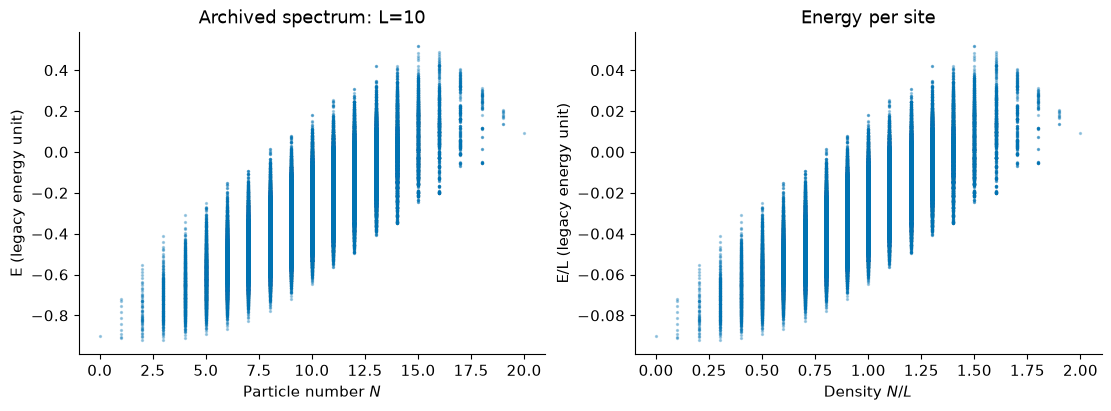

Saved phase parameter: 0.0 ; saved levels: 59049
Sector minima: [(0, -0.8999999999999999), (1, -0.9119760858605935), (2, -0.9193344948131369), (3, -0.9192076910146696), (4, -0.910373805288799)]


In [4]:
with np.load(ROOT / 'data/heff2_E_vs_N_L10.npz', allow_pickle=False) as z:
    cached_L = int(z['L'])
    energy = z['E'].copy()
    number = z['NLAB'].copy()
    cached_angle = float(z['theta'])
assert len(energy) == len(number) == 3**cached_L
assert np.all((0 <= number) & (number <= 2*cached_L))
with plt.rc_context(STYLE):
    fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout='constrained')
    axes[0].scatter(number, energy, s=2, alpha=0.3, color='#0072B2', rasterized=True)
    axes[1].scatter(number/cached_L, energy/cached_L, s=2, alpha=0.3,
                    color='#0072B2', rasterized=True)
    axes[0].set(xlabel=r'Particle number $N$', ylabel='E (legacy energy unit)',
                title=f'Archived spectrum: L={cached_L}')
    axes[1].set(xlabel=r'Density $N/L$', ylabel='E/L (legacy energy unit)',
                title='Energy per site')
    show_figure(fig, '01_cached_spectrum')
print('Saved phase parameter:', cached_angle, '; saved levels:', len(energy))
print('Sector minima:', [(N, float(energy[number == N].min())) for N in range(5)])

**Figure description:** the two panels show the same archived levels, first
against integer particle number and then with both axes divided by chain
length. The printed sector minima provide numerical values independent of
the colour encoding. A global nearest-level spacing can connect different
particle numbers; it is not automatically a fixed-filling excitation gap.

## 1.5 Limiting and convergence checks

With all hopping rates zero, $K$ is diagonal and its eigenvalues are its
diagonal entries. With phases zero and real rates, $K$ is real symmetric.
Increasing the sideband cutoff should stabilize retained rates; this checks
the finite sum, not the validity of perturbation theory itself.

In [5]:
frozen, _ = effective_chain(4, diagonal, np.zeros(4), total_number=2)
assert np.allclose(np.linalg.eigvalsh(frozen), np.sort(frozen.diagonal().real))
assert np.max(abs(H.imag)) == 0
_, g40, _ = effective_bond(replace(p, sideband_cutoff=40))
_, g80, _ = effective_bond(replace(p, sideband_cutoff=80))
print('Sideband rate change (40 -> 80):', np.max(abs(g80-g40)))
assert np.allclose(g40, g80, atol=1e-12)

Sideband rate change (40 -> 80): 0.0


## Sources and limits of this notebook

- Aditya Banerjee, *Linear Anyon Model with Rydberg Atoms*, Universitat de
  Barcelona, 2026: [institutional record](https://hdl.handle.net/2445/231684).
  See the relevant sections and equations identified above.
- [Archived thesis and code deposit](https://doi.org/10.5281/zenodo.23443035).
- Original scripts in [`scripts/`](../scripts/) at source commit
  `22959963191fcbc4d283ec4b272b506ad6dd979b`; this notebook is a new explanatory
  implementation. The original script and data bytes are preserved.
- [SciPy `eigsh` documentation](https://docs.scipy.org/doc/scipy/reference/generated/scipy.sparse.linalg.eigsh.html)
  for the sparse eigenvalue solver. For complex Hermitian input, SciPy uses
  its complex eigensolver internally; residual checks remain necessary.

These finite-size calculations do not independently validate the microscopic
derivation, establish an experimental realization, or prove a thermodynamic
phase transition. No new empirical evidence is introduced.